# Olist: как доставка влияет на оценку отзыва

**Вопрос:** почему клиенты бразильского маркетплейса Olist ставят плохие оценки, и насколько в этом виновата доставка?

План ноутбука:
1. Загрузка данных.
2. Проверка данных: пропуски, дубликаты, логические несоответствия в датах — и что я с ними сделал.
3. Связь опоздания (в днях) и средней оценки.
4. Три главные находки в графиках.
5. Выводы.

Агрегаты для SQL-части лежат в `queries.sql`, здесь те же метрики считаются в pandas — цифры совпадают.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
from matplotlib import font_manager

DATA = Path("data")
IMG = Path("images")
IMG.mkdir(exist_ok=True)

# --- Единый стиль графиков ---------------------------------------------------
# Синий — «вовремя / норма», оранжевый — «опоздание / проблема», серый — фон.
BLUE, BLUE_L = "#2a78d6", "#a9c9f0"
ORANGE, ORANGE_L = "#eb6834", "#f6bfa3"
GRAY, GRAY_L = "#8a8984", "#dcdbd6"
INK, MUTED = "#1f1f1e", "#6b6a66"
FONT = "Segoe UI" if any(f.name == "Segoe UI" for f in font_manager.fontManager.ttflist) else "DejaVu Sans"

plt.rcParams.update({
    "font.family": [FONT, "Segoe UI Symbol", "DejaVu Sans"],  # запасные шрифты для ★ и − "font.size": 10.5, "text.color": INK,
    "axes.labelcolor": MUTED, "axes.labelsize": 10, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.major.size": 0, "ytick.major.size": 0, "xtick.major.pad": 6, "ytick.major.pad": 6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": GRAY_L, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.facecolor": "white", "axes.facecolor": "white", "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "savefig.pad_inches": 0.3,
})


def headline(ax, title, subtitle=None, lift=0):
    # Заголовок-вывод + пояснение, выровненные по левому краю графика
    ax.annotate(title, xy=(0, 1), xycoords="axes fraction", xytext=(0, (44 if subtitle else 18) + lift),
                textcoords="offset points", fontsize=15, fontweight="bold", color=INK, va="bottom")
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 18 + lift),
                    textcoords="offset points", fontsize=10.5, color=MUTED, va="bottom")


def source(ax, text="Данные: Olist, доставленные заказы с отзывом, 2016–2018"):
    ax.annotate(text, xy=(0, 0), xycoords="figure fraction", xytext=(8, 4),
                textcoords="offset points", fontsize=8.5, color=GRAY)


def ru(x, nd=1):
    # Число с запятой: 4.29 -> «4,3»
    return f"{x:.{nd}f}".replace(".", ",").replace("-", "−")


COMMA = mtick.FuncFormatter(lambda v, _: ru(v))


pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders    = pd.read_csv(DATA / "olist_orders_dataset.csv", parse_dates=date_cols)
items     = pd.read_csv(DATA / "olist_order_items_dataset.csv")
reviews   = pd.read_csv(DATA / "olist_order_reviews_dataset.csv",
                        parse_dates=["review_creation_date", "review_answer_timestamp"])
products  = pd.read_csv(DATA / "olist_products_dataset.csv")
customers = pd.read_csv(DATA / "olist_customers_dataset.csv")
sellers   = pd.read_csv(DATA / "olist_sellers_dataset.csv")
cat_en    = pd.read_csv(DATA / "product_category_name_translation.csv")

tables = dict(orders=orders, items=items, reviews=reviews, products=products,
              customers=customers, sellers=sellers)
pd.DataFrame({name: [len(df), df.shape[1]] for name, df in tables.items()},
             index=["строк", "столбцов"]).T

,строк,столбцов
orders,99441,8
items,112650,7
reviews,99224,7
products,32951,9
customers,99441,5
sellers,3095,4


## 1. Проверка данных

Проверяю три вещи: пропуски, дубликаты и логику дат (доставка не может быть раньше покупки, передача перевозчику — раньше оплаты и т.д.).

### 1.1 Пропуски

In [3]:
na = pd.concat({name: df.isna().sum() for name, df in tables.items()})
na = na[na > 0].rename("пропусков").to_frame()
na["доля, %"] = [100 * v / len(tables[t]) for (t, _), v in na["пропусков"].items()]
na

пропусков  доля, %
orders   order_approved_at                    160     0.16
         order_delivered_carrier_date        1783     1.79
         order_delivered_customer_date       2965     2.98
reviews  review_comment_title               87656    88.34
         review_comment_message             58247    58.70
products product_category_name                610     1.85
         product_name_lenght                  610     1.85
         product_description_lenght           610     1.85
         product_photos_qty                   610     1.85
         product_weight_g                       2     0.01
         product_length_cm                      2     0.01
         product_height_cm                      2     0.01
         product_width_cm                       2     0.01

In [4]:
# Пропуски в датах доставки — это нормально для недоставленных заказов? Проверяем по статусам.
pd.crosstab(orders["order_status"], orders["order_delivered_customer_date"].isna(),
            margins=True).rename(columns={False: "дата есть", True: "даты нет"})

order_delivered_customer_date,дата есть,даты нет,All
order_status,,,
approved,0,2,2
canceled,6,619,625
created,0,5,5
delivered,96470,8,96478
invoiced,0,314,314
processing,0,301,301
shipped,0,1107,1107
unavailable,0,609,609
All,96476,2965,99441


### 1.2 Дубликаты

In [5]:
multi_review = reviews.groupby("order_id").size()
shared_review_id = reviews.drop_duplicates(["review_id", "order_id"])["review_id"].duplicated()

pd.Series({
    "дубли order_id в orders":                    orders["order_id"].duplicated().sum(),
    "полные дубли строк в reviews":               reviews.duplicated().sum(),
    "полные дубли строк в items":                 items.duplicated().sum(),
    "заказов с >1 отзывом":                       (multi_review > 1).sum(),
    "review_id, привязанный к нескольким заказам": shared_review_id.sum(),
    "заказов без отзыва":                         (~orders["order_id"].isin(reviews["order_id"])).sum(),
}, name="количество").to_frame()

,количество
дубли order_id в orders,0
полные дубли строк в reviews,0
полные дубли строк в items,0
заказов с >1 отзывом,547
"review_id, привязанный к нескольким заказам",814
заказов без отзыва,768


### 1.3 Несоответствия в датах

In [6]:
o = orders
checks = {
    "доставка клиенту раньше покупки":   o["order_delivered_customer_date"] < o["order_purchase_timestamp"],
    "оплата одобрена раньше покупки":    o["order_approved_at"] < o["order_purchase_timestamp"],
    "передача перевозчику раньше покупки": o["order_delivered_carrier_date"] < o["order_purchase_timestamp"],
    "доставка клиенту раньше передачи перевозчику": o["order_delivered_customer_date"] < o["order_delivered_carrier_date"],
    "статус delivered, но даты доставки нет": (o["order_status"] == "delivered") & o["order_delivered_customer_date"].isna(),
    "статус не delivered, но дата доставки есть": (o["order_status"] != "delivered") & o["order_delivered_customer_date"].notna(),
}
purchase_by_order = o.set_index("order_id")["order_purchase_timestamp"].dt.normalize()
checks_reviews = reviews["review_creation_date"] < reviews["order_id"].map(purchase_by_order)

issues = pd.Series({k: v.sum() for k, v in checks.items()}, name="заказов").to_frame()
issues.loc["отзыв создан раньше дня покупки"] = checks_reviews.sum()
issues

,заказов
доставка клиенту раньше покупки,0
оплата одобрена раньше покупки,0
передача перевозчику раньше покупки,166
доставка клиенту раньше передачи перевозчику,23
"статус delivered, но даты доставки нет",8
"статус не delivered, но дата доставки есть",6
отзыв создан раньше дня покупки,64


In [7]:
# Пример: заказы, переданные перевозчику раньше, чем были куплены
o.loc[checks["передача перевозчику раньше покупки"],
      ["order_id", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date"]].head()

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date
615,b9afddbdcfadc9a87b41a83271c3e888,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00
1111,ad133696906f6a78826daa0911b7daec,2018-06-15 15:41:22,2018-06-15 16:19:23,2018-06-15 14:52:00
1329,74e033208dc13a7b8127eb8e73d09b76,2018-05-02 10:48:44,2018-05-02 11:13:45,2018-05-02 09:49:00
1372,a6b58794fd2ba533359a76c08df576e3,2018-05-14 15:18:23,2018-05-14 15:33:35,2018-05-14 13:46:00
1864,5792e0b1c8c8a2bf53af468c9a422c88,2018-07-26 13:25:14,2018-07-26 13:35:14,2018-07-26 12:42:00


### 1.4 Что нашёл в данных и что с этим сделал

| Находка | Масштаб | Решение |
|---|---|---|
| Пропуски в датах доставки | ~3% заказов, почти все — недоставленные статусы (shipped, canceled, unavailable…) | Это не ошибка, а состояние заказа. В анализ доставки беру только `delivered` с заполненной датой |
| `delivered` без даты доставки | 8 заказов | Исключил из анализа сроков: нельзя посчитать опоздание |
| `canceled`, но с датой доставки | 6 заказов | Исключил: статус противоречит факту, верить нельзя ни тому, ни другому |
| Доставка раньше покупки | **0** | Проверка пройдена — грубых ошибок в ключевой дате нет |
| Передача перевозчику раньше покупки | 166 заказов | Ошибка учёта на стороне продавца/логистики. На метрику опоздания не влияет (она считается по дате доставки клиенту), поэтому заказы оставил, но этой датой не пользуюсь |
| Доставка клиенту раньше передачи перевозчику | 23 заказа | Аналогично: дата передачи перевозчику ненадёжна, в метриках её не использую |
| Отзыв создан раньше дня покупки | 64 отзыва | Мало, на средние не влияет. Оставил, отметил как известную аномалию |
| Несколько отзывов на один заказ | 547 заказов | Усредняю оценку до уровня заказа, иначе такие заказы весят в 2–3 раза больше |
| Один `review_id` на несколько заказов | 814 случаев | Похоже, клиент оставил один отзыв на покупку, разбитую на несколько заказов. Оставил: для каждого заказа это его реальная оценка |
| Товары без категории | 610 товаров | Помечаю как `unknown`, не выбрасываю — иначе теряется выручка |
| Пропуски в тексте отзыва | 59–88% | Норма: текст необязателен. Работаю только с оценкой |

**Итог:** данные в целом чистые; главное — правильно выбрать знаменатель (только доставленные заказы с датой) и не задвоить оценки.

In [8]:
# Чистый набор для анализа доставки: один заказ = одна строка, одна (средняя) оценка
order_score = reviews.groupby("order_id")["review_score"].mean().rename("score")

d = orders[(orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].notna()].copy()
d = d.join(order_score, on="order_id", how="inner")
d = d.merge(customers[["customer_id", "customer_state"]], on="customer_id")

# Опоздание в днях: положительное — опоздали, отрицательное — привезли раньше обещанного
d["delay_days"] = (d["order_delivered_customer_date"].dt.normalize() - d["order_estimated_delivery_date"]).dt.days
d["is_late"] = d["delay_days"] > 0
d["bad"] = d["score"] <= 2
d["month"] = d["order_purchase_timestamp"].dt.to_period("M")
print(f"Заказов в анализе: {len(d):,}; опоздали: {d['is_late'].mean():.1%}")

Заказов в анализе: 95,824; опоздали: 6.7%


## 2. Опоздание и оценка

Главный вопрос: как меняется средняя оценка с каждым днём опоздания. Беру диапазон от −30 до +30 дней и показываю только точки, где хотя бы 30 заказов, чтобы хвосты не шумели.

findfont: Failed to find font weight bold for Segoe UI Symbol, now using 400.


findfont: Failed to find font weight bold for Segoe UI Symbol, now using 400.


findfont: Failed to find font weight bold for Segoe UI Symbol, now using 400.


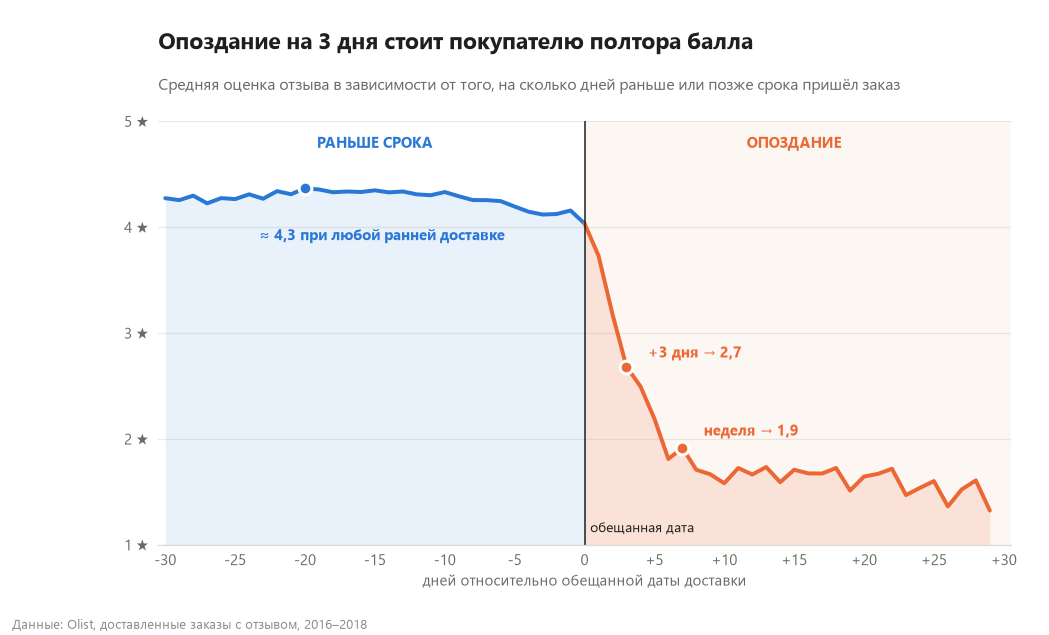

,orders,avg_score
delay_days,,
-10,4618,4.33
-5,2208,4.20
0,1280,4.04
1,820,3.73
2,536,3.18
3,496,2.68
5,434,2.19
7,471,1.92
10,207,1.58


In [9]:
by_delay = d.groupby("delay_days").agg(orders=("score", "size"), avg_score=("score", "mean"))
curve = by_delay[(by_delay.index.to_series().between(-30, 30)) & (by_delay["orders"] >= 30)]
x, y = curve.index, curve["avg_score"]
early, late = x <= 0, x >= 0

fig, ax = plt.subplots(figsize=(10, 5))
ax.axvspan(0, 30.5, color=ORANGE, alpha=0.05, lw=0)
ax.fill_between(x[early], y[early], 1, color=BLUE, alpha=0.10, lw=0)
ax.fill_between(x[late], y[late], 1, color=ORANGE, alpha=0.14, lw=0)
ax.plot(x[early], y[early], color=BLUE, lw=2.6, solid_capstyle="round")
ax.plot(x[late], y[late], color=ORANGE, lw=2.6, solid_capstyle="round")
ax.axvline(0, color=INK, lw=1)

ax.text(-15, 4.75, "РАНЬШЕ СРОКА", color=BLUE, fontsize=9.5, fontweight="bold", ha="center")
ax.text(15, 4.75, "ОПОЗДАНИЕ", color=ORANGE, fontsize=9.5, fontweight="bold", ha="center")
ax.text(0.4, 1.12, "обещанная дата", color=INK, fontsize=9)

for day, text, color, dx, dy in [(-20, "≈ 4,3 при любой ранней доставке", BLUE, -30, -34),
                                 (3, f"+3 дня → {ru(y[3])}", ORANGE, 14, 6),
                                 (7, f"неделя → {ru(y[7])}", ORANGE, 14, 8)]:
    ax.scatter(day, y[day], s=70, color=color, edgecolor="white", linewidth=2, zorder=5)
    ax.annotate(text, (day, y[day]), xytext=(dx, dy), textcoords="offset points",
                fontsize=10, fontweight="bold", color=color)

ax.set_xlim(-30.5, 30.5)
ax.set_ylim(1, 5)
ax.set_xticks(range(-30, 31, 5), [f"{t:+d}" if t else "0" for t in range(-30, 31, 5)])
ax.set_yticks([1, 2, 3, 4, 5], ["1 ★", "2 ★", "3 ★", "4 ★", "5 ★"])
ax.set_xlabel("дней относительно обещанной даты доставки")
headline(ax, "Опоздание на 3 дня стоит покупателю полтора балла",
         "Средняя оценка отзыва в зависимости от того, на сколько дней раньше или позже срока пришёл заказ")
source(ax)
fig.savefig(IMG / "01_delay_vs_score.png")
plt.show()

curve.loc[[-10, -5, 0, 1, 2, 3, 5, 7, 10, 14, 20]].round(2)

Кривая почти плоская слева от нуля: привезти на 5 или на 20 дней раньше — для клиента одно и то же (≈4,3). Обвал начинается ровно с даты обещания: +1 день — 3,7, **+3 дня — уже 2,7** (минус 1,6 балла к «вовремя»), а после недели опоздания средняя оценка опускается до 1,6–1,9. Значит, клиент оценивает не скорость доставки, а **выполнение обещания**.

## 3. Главные находки

### 3.1 Вовремя vs с опозданием: опоздание превращает отзыв в жалобу

,orders,avg_score,bad_pct
is_late,,,
вовремя,89443,4.29,9.23
с опозданием,6381,2.27,62.36


findfont: Failed to find font weight bold for Segoe UI Symbol, now using 400.


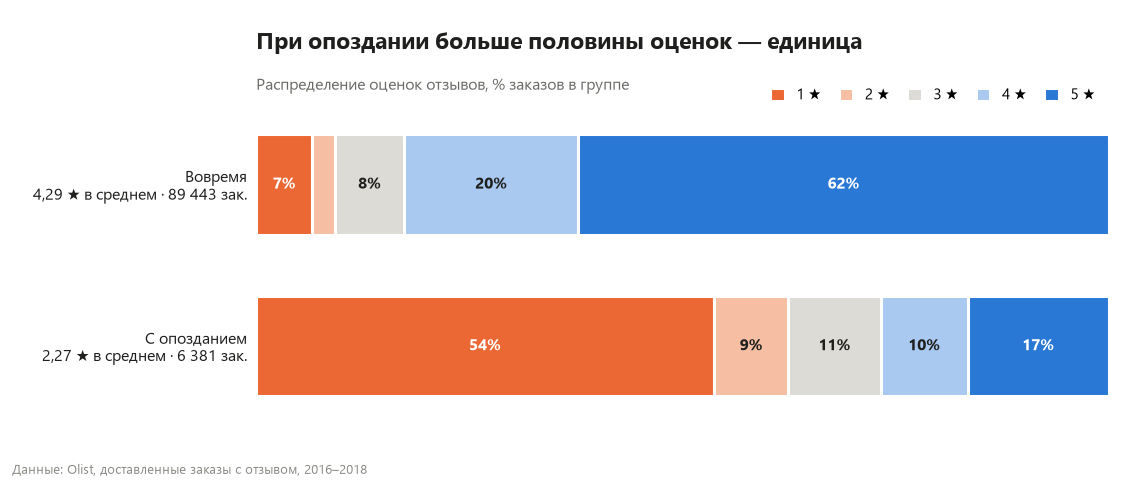

In [10]:
summary = d.groupby("is_late").agg(orders=("score", "size"), avg_score=("score", "mean"),
                                   bad_pct=("bad", "mean")).rename(index={False: "вовремя", True: "с опозданием"})
summary["bad_pct"] *= 100
display(summary.round(2))

# Распределение оценок 1–5 в каждой группе, 100%-я горизонтальная полоса
dist = (pd.crosstab(d["is_late"], d["score"].round().astype(int), normalize="index") * 100
        ).rename(index={False: "вовремя", True: "с опозданием"})
score_colors = {1: ORANGE, 2: ORANGE_L, 3: GRAY_L, 4: BLUE_L, 5: BLUE}

fig, ax = plt.subplots(figsize=(10, 3.4))
rows = ["с опозданием", "вовремя"]  # снизу вверх
for r, grp in enumerate(rows):
    left = 0
    for s in range(1, 6):
        v = dist.loc[grp, s]
        ax.barh(r, v, left=left, height=0.62, color=score_colors[s], edgecolor="white", linewidth=2,
                label=f"{s} ★" if r == 0 else None)
        if v >= 5:
            ax.text(left + v / 2, r, f"{v:.0f}%", ha="center", va="center", fontsize=10.5, fontweight="bold",
                    color="white" if s in (1, 5) else INK)
        left += v
labels = [g.capitalize() + "\n" + f"{ru(summary.loc[g, 'avg_score'], 2)} ★ в среднем · "
          + f"{summary.loc[g, 'orders']:,}".replace(",", " ") + " зак."
          for g in rows]
ax.set_yticks([0, 1], labels)
ax.tick_params(axis="y", labelsize=10.5, labelcolor=INK)
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
ax.legend(ncol=5, loc="lower right", bbox_to_anchor=(1, 1.02), handlelength=1, handleheight=1,
          columnspacing=1.2, fontsize=9.5)
headline(ax, "При опоздании больше половины оценок — единица",
         "Распределение оценок отзывов, % заказов в группе")
source(ax)
fig.savefig(IMG / "02_score_distribution.png")
plt.show()

Заказы, доставленные с опозданием, — это ~7% всех доставок, но среди них **более 60% оценок 1–2** против ~9% у доставленных вовремя. Распределение «переворачивается»: у вовремя доставленных мода — 5 звёзд, у опоздавших — 1 звезда.

### 3.2 Опоздания по месяцам: провалы после пиков спроса

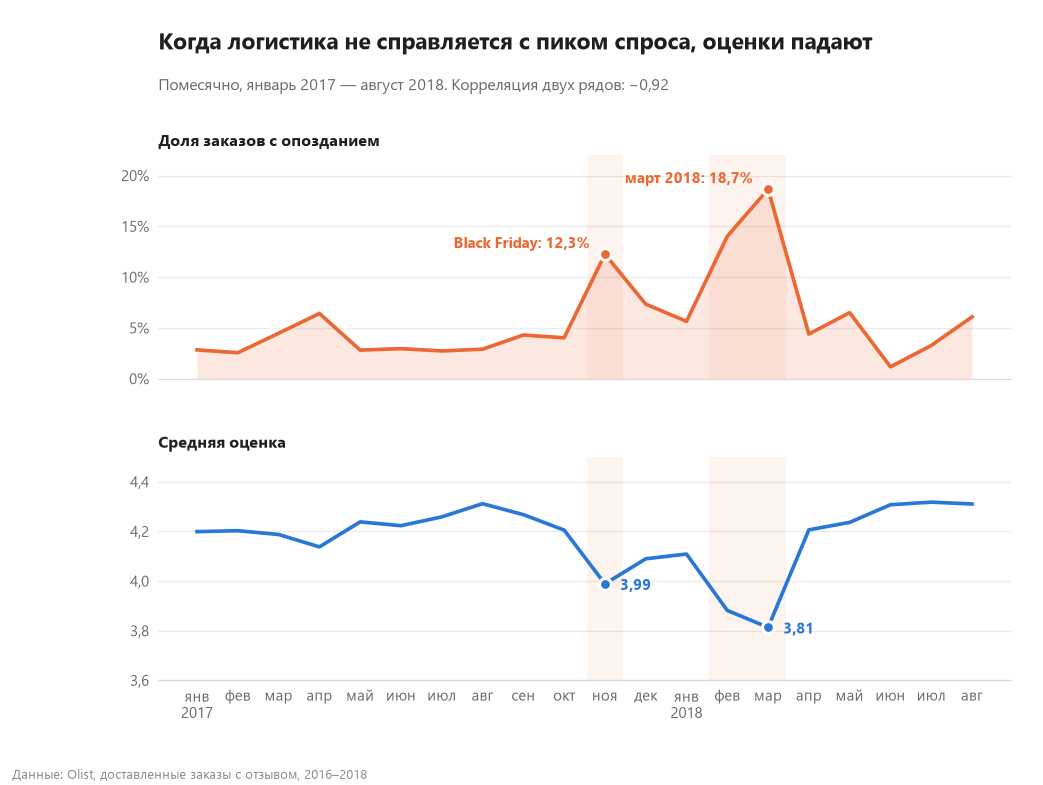

Корреляция доли опозданий и средней оценки по месяцам: -0.92


month,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
orders,741.00,"1,643.00","2,527.00","2,290.00","3,517.00","3,111.00","3,842.00","4,165.00","4,118.00","4,446.00","7,237.00","5,461.00","7,013.00","6,507.00","6,948.00","6,752.00","6,722.00","6,072.00","6,118.00","6,330.00"
late_pct,2.83,2.56,4.47,6.42,2.81,2.96,2.73,2.91,4.30,4.03,12.26,7.34,5.65,14.02,18.65,4.40,6.50,1.17,3.27,6.08
avg_score,4.20,4.20,4.19,4.14,4.24,4.22,4.26,4.31,4.27,4.21,3.99,4.09,4.11,3.88,3.81,4.21,4.24,4.31,4.32,4.31


In [11]:
monthly = d.groupby("month").agg(orders=("score", "size"), late_pct=("is_late", "mean"),
                                 avg_score=("score", "mean"))
monthly = monthly[monthly["orders"] >= 500]  # отрезаем неполные месяцы на краях
monthly["late_pct"] *= 100
corr = monthly["late_pct"].corr(monthly["avg_score"])

MON = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
xs = range(len(monthly))
xlabels = [f"{MON[p.month - 1]}\n{p.year}" if p.month == 1 or i == 0 else MON[p.month - 1]
           for i, p in enumerate(monthly.index)]
pos = {str(p): i for i, p in enumerate(monthly.index)}

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True, gridspec_kw={"hspace": 0.35})
for a in (a1, a2):  # пиковые периоды
    a.axvspan(pos["2017-11"] - 0.45, pos["2017-11"] + 0.45, color=ORANGE, alpha=0.08, lw=0)
    a.axvspan(pos["2018-02"] - 0.45, pos["2018-03"] + 0.45, color=ORANGE, alpha=0.08, lw=0)

a1.fill_between(xs, monthly["late_pct"], 0, color=ORANGE, alpha=0.15, lw=0)
a1.plot(xs, monthly["late_pct"], color=ORANGE, lw=2.4)
a1.set_ylim(0, 22)
a1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a1.set_title("Доля заказов с опозданием", loc="left", fontsize=10.5, fontweight="bold", color=INK, pad=6)
for m, text in [("2017-11", "Black Friday"), ("2018-03", "март 2018")]:
    v = monthly.loc[m, "late_pct"]
    a1.scatter(pos[m], v, s=60, color=ORANGE, edgecolor="white", linewidth=2, zorder=5)
    a1.annotate(f"{text}: {ru(v)}%", (pos[m], v), xytext=(-10, 4), textcoords="offset points", ha="right",
                fontsize=9.5, fontweight="bold", color=ORANGE)

a2.plot(xs, monthly["avg_score"], color=BLUE, lw=2.4)
a2.set_ylim(3.6, 4.5)
a2.yaxis.set_major_formatter(COMMA)
a2.set_title("Средняя оценка", loc="left", fontsize=10.5, fontweight="bold", color=INK, pad=6)
for m in ("2017-11", "2018-03"):
    v = monthly.loc[m, "avg_score"]
    a2.scatter(pos[m], v, s=60, color=BLUE, edgecolor="white", linewidth=2, zorder=5)
    a2.annotate(ru(v, 2), (pos[m], v), xytext=(10, -4), textcoords="offset points",
                fontsize=9.5, fontweight="bold", color=BLUE)
a2.set_xticks(list(xs), xlabels)
headline(a1, "Когда логистика не справляется с пиком спроса, оценки падают",
         f"Помесячно, январь 2017 — август 2018. Корреляция двух рядов: {ru(corr, 2)}", lift=22)
source(a2)
fig.savefig(IMG / "03_monthly_late_vs_score.png")
plt.show()

print("Корреляция доли опозданий и средней оценки по месяцам:", round(corr, 2))
monthly.round(2).T

Две вспышки опозданий — ноябрь 2017 (Black Friday) и февраль–март 2018 — и в обоих случаях средняя оценка месяца проседает. Помесячно доля опозданий и средняя оценка связаны почти линейно (корреляция около −0,9). Логистика не масштабируется под пиковый спрос, и это сразу бьёт по репутации.

### 3.3 География: опоздания концентрируются на северо-востоке

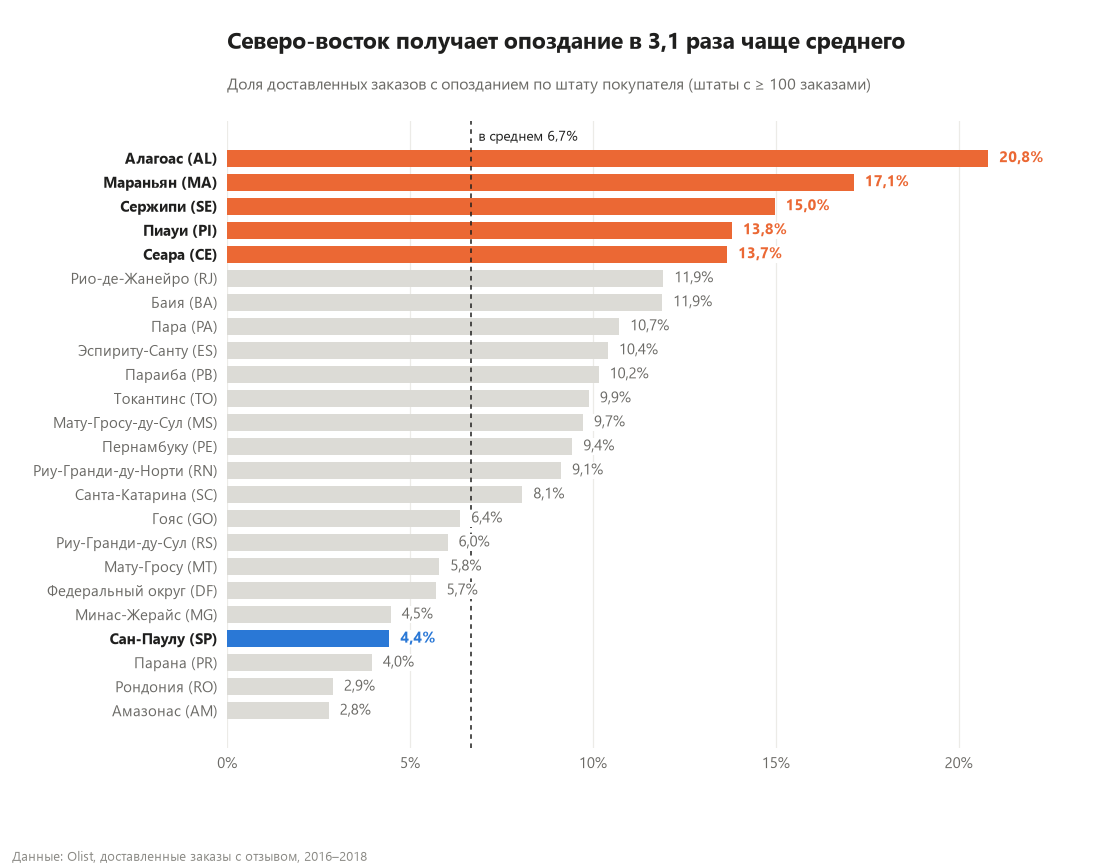

In [12]:
STATE_RU = {"AC": "Акри", "AL": "Алагоас", "AM": "Амазонас", "AP": "Амапа", "BA": "Баия", "CE": "Сеара",
            "DF": "Федеральный округ", "ES": "Эспириту-Санту", "GO": "Гояс", "MA": "Мараньян",
            "MG": "Минас-Жерайс", "MS": "Мату-Гросу-ду-Сул", "MT": "Мату-Гросу", "PA": "Пара", "PB": "Параиба",
            "PE": "Пернамбуку", "PI": "Пиауи", "PR": "Парана", "RJ": "Рио-де-Жанейро",
            "RN": "Риу-Гранди-ду-Норти", "RO": "Рондония", "RR": "Рорайма", "RS": "Риу-Гранди-ду-Сул",
            "SC": "Санта-Катарина", "SE": "Сержипи", "SP": "Сан-Паулу", "TO": "Токантинс"}

states = d.groupby("customer_state").agg(orders=("score", "size"), late_pct=("is_late", "mean"),
                                         avg_score=("score", "mean"))
states["late_pct"] *= 100
states = states[states["orders"] >= 100].sort_values("late_pct")
overall = d["is_late"].mean() * 100
top5 = states.index[-5:]

fig, ax = plt.subplots(figsize=(10, 7.4))
colors = [ORANGE if s in top5 else BLUE if s == "SP" else GRAY_L for s in states.index]
ax.barh(range(len(states)), states["late_pct"], color=colors, height=0.72)
ax.axvline(overall, color=INK, lw=1, ls=(0, (3, 3)), zorder=1)
ax.annotate(f"в среднем {ru(overall)}%", (overall, len(states) - 0.4), xytext=(5, 0),
            textcoords="offset points", fontsize=9, color=INK, va="bottom")
for i, (s, v) in enumerate(states["late_pct"].items()):
    hl = s in top5 or s == "SP"
    ax.text(v + 0.3, i, f"{ru(v)}%", va="center", fontsize=9.5,
            fontweight="bold" if hl else "normal", color=ORANGE if s in top5 else BLUE if s == "SP" else MUTED,
            bbox=dict(fc="white", ec="none", pad=1), zorder=3)
ax.set_yticks(range(len(states)), [f"{STATE_RU[s]} ({s})" for s in states.index])
for lbl, s in zip(ax.get_yticklabels(), states.index):
    if s in top5 or s == "SP":
        lbl.set_color(INK)
        lbl.set_fontweight("bold")
ax.set_xlim(0, states["late_pct"].max() * 1.12)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.spines["bottom"].set_visible(False)
headline(ax, f"Северо-восток получает опоздание в {ru(states['late_pct'].max() / overall)} раза чаще среднего",
         "Доля доставленных заказов с опозданием по штату покупателя (штаты с ≥ 100 заказами)")
source(ax)
fig.savefig(IMG / "04_late_by_state.png")
plt.show()

Оранжевым выделены пять штатов с самой высокой долей опозданий — Алагоас (AL), Мараньян (MA), Сержипи (SE), Пиауи (PI), Сеара (CE): все на северо-востоке, далеко от продавцов, которые в основном сидят в Сан-Паулу. Синим — сам Сан-Паулу (SP) для сравнения: 4,4% опозданий. Отдельно выделяется Рио (RJ): 12% опозданий при огромном объёме заказов. (Цифры чуть отличаются от запроса 4 в SQL: здесь в знаменателе только заказы с отзывом.) Обещанный срок для дальних штатов занижен относительно реальной логистики.

## 4. Выводы

1. **Опоздание — главный драйвер плохих отзывов.** Средняя оценка: ~4,3 вовремя против ~2,3 с опозданием; доля оценок 1–2 растёт с ~9% до ~62%.
2. **Важна не скорость, а обещание.** Приехать на 20 дней раньше даёт ту же оценку, что и на 5 дней раньше; а уже 3 дня опоздания снижают её с ~4,3 до 2,7.
3. **Опоздания сезонны.** Пики в ноябре 2017 и феврале–марте 2018 совпадают с провалами средней оценки.
4. **Опоздания географичны.** Северо-восток (AL, MA, SE, PI, CE) получает опоздание в 14–21% заказов против 6,7% в среднем и 4,4% в Сан-Паулу.

**Что из этого следует для бизнеса** — в README: пересчитать обещанную дату для дальних штатов и пиковых месяцев, мониторить продавцов с высокой долей плохих отзывов и опозданий (см. запрос 6 в `queries.sql` и VBA-письмо в `report.xlsm`).